<a href="https://colab.research.google.com/github/showravj2-create/Nuroserge_U_r/blob/main/Copy_of_3D_MRI_Brain_Tumor_Segmentation%7C%7C_U_NET.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Problem Defination
Segmentation of gliomas in pre-operative MRI scans


In [1]:
#Env Setup
import os
import cv2
import glob
import PIL
import shutil
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from skimage import data
from skimage.util import montage
import skimage.transform as skTrnas
from skimage.transform import rotate
from skimage.transform import resize
from PIL import Image, ImageOps

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [2]:
#Nural Imaging
!pip install nilearn
import nilearn as nl
import nibabel as nib
import nilearn.plotting as nlplt

In [3]:
!pip install git+https://github.com/miykael/gif_your_nifti #nifti to gif
import gif_your_nifti as gif2nif

  Cloning https://github.com/miykael/gif_your_nifti to /tmp/pip-req-build-r03zzwdc
  Running command git clone --filter=blob:none --quiet https://github.com/miykael/gif_your_nifti /tmp/pip-req-build-r03zzwdc
  Resolved https://github.com/miykael/gif_your_nifti to commit 55c09c42921f4871cf43f63a303ab420a92a4f03
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for gif_your_nifti: filename=gif_your_nifti-0.2.2-py3-none-any.whl size=6691 sha256=52f2f2f1caa7fd863bcd2aa86707052816160dab7f27c27f086d5a98561319c5
  Stored in directory: /tmp/pip-ephem-wheel-cache-lzcii32n/wheels/ef/8b/bb/e56d789445a65ff3230cedd98126c3a11d30703883107f5163
Successfully built gif_your_nifti


/usr/local/lib/python3.13/dist-packages/gif_your_nifti/__init__.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [4]:
# Machine Learning Libraries
import keras
import keras.backend as K
from keras.callbacks import CSVLogger
import tensorflow as tf
from tensorflow.keras.utils import plot_model
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from tensorflow.keras.models import *
from tensorflow.keras.layers import *
from tensorflow.keras.optimizers import *
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau, EarlyStopping, TensorBoard
from tensorflow.keras import layers


In [5]:
#Make Numpy Printouts easier to read
np.set_printoptions(precision=3, suppress=True)

In [6]:
#Define Segmentation areas
SEGMENT_CLASSES = {
    0: "NOT TUMOR",
    1: "NECROTIC/CORE",# OR NON-ENHANCING TUMOR CORE
    2: "EDEMA",
    3: "ENHANCING" # ORIGINAL 4 -> CONVERTED INTO 3 LATER
}
#THERE ARE 155 SLICES PER VOLUME
#TO START AT 5 AND USE 145 SLICES MEANS WE WILL SKIP THE FIRST 5 AND LAST 5
VOLUME_SLICES = 100
VOLUME_START_AT = 22 #First slice of the volume we will include

In [7]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("awsaf49/brats20-dataset-training-validation")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'brats20-dataset-training-validation' dataset.
Path to dataset files: /kaggle/input/brats20-dataset-training-validation


#IMAGE DATA DESCRIPTION
All BraTS multimodal scans are available as NIFTI files(.nni.gz)->commonly used in medical imaging format to store brain imaging data obtained using MRI and describe different MRI settings.


1.   **T1**: T1 Weighted , native image, sagittal or axial 2D acquisitions, with 1-6 mm slice thickness.

2.  **T1c**:T1 weighted, contrast-enhanced (Gadolinium) image, with 3D acquisition and 1 mm isotropic voxel size for most patients.

3.  **T2**:T2-weighted image, axial 2D acquisitions, with 2-6 mm slice thickness.

4.  **FLAIR**:T2-Weighted FLAIR image, axial, coronal, or sagittal 2D acquisitions, 2-6 mm slice thickness.

Data were acquired with different clinical proticols and various scanners from multiple (n=19) institutions.

All the imaging datasets have been segmented manually, by one to four raters, following the same annotion protocol, and their annotations were approved by experienced neuro-radiologists.Annotations comprise the GD-enhancing tumor(ET--label 4), the peritumorial edema(ED--label 2),and the necrotic and non-enhancing tumor core (NCR/NET -- label 1), as described both in the BraTS 2021-13 TMI paper and in the  latest BraTS summarizing paper. The provided data are distributed after their pre-processing, i.e., co-registered to the same anatomical template, interpolated to the same resolution (1 mm^3) and skull-stripped.



Text(0.5, 1.0, 'Mask')

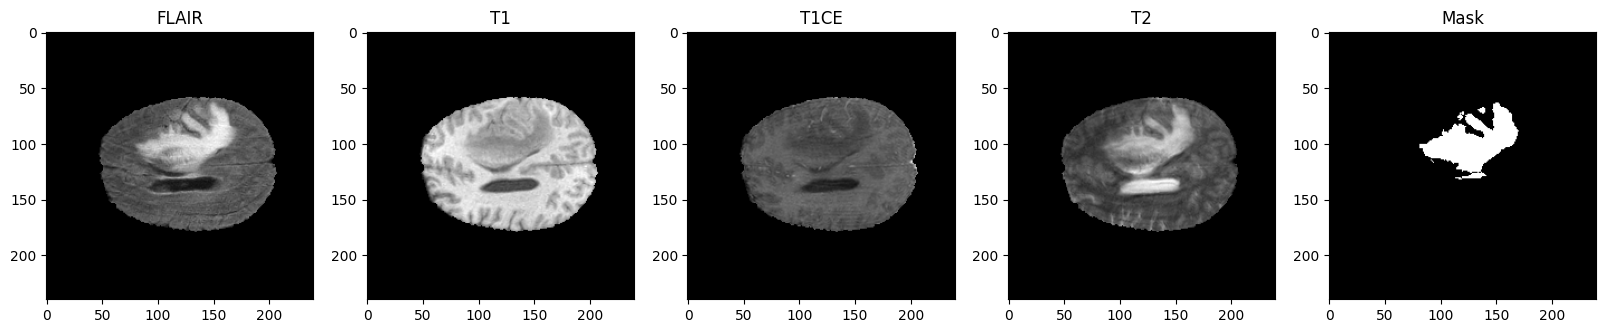

In [8]:
TRAIN_DATASET_PATH = '/kaggle/input/brats20-dataset-training-validation/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData'
VALIDATION_DATASET_PATH = '/kaggle/input/brats20-dataset-training-validation/BraTS2020_ValidationData/MICCAI_BraTS2020_ValidationData'

test_image_flair=nib.load(TRAIN_DATASET_PATH + '/BraTS20_Training_001/BraTS20_Training_001_flair.nii').get_fdata()

test_image_t1=nib.load(TRAIN_DATASET_PATH + '/BraTS20_Training_001/BraTS20_Training_001_t1.nii').get_fdata()

test_image_t1ce=nib.load(TRAIN_DATASET_PATH + '/BraTS20_Training_001/BraTS20_Training_001_t1ce.nii').get_fdata()

test_image_t2=nib.load(TRAIN_DATASET_PATH + '/BraTS20_Training_001/BraTS20_Training_001_t2.nii').get_fdata()

test_mask=nib.load(TRAIN_DATASET_PATH + '/BraTS20_Training_001/BraTS20_Training_001_seg.nii').get_fdata()

fig, (ax1, ax2, ax3, ax4, ax5) = plt.subplots(1,5, figsize=(20,10))
slice_w = 25
ax1.imshow(test_image_flair[:,:,test_image_flair.shape[0]//2-slice_w], cmap='gray')
ax1.set_title('FLAIR')

ax2.imshow(test_image_t1[:,:,test_image_t1.shape[0]//2-slice_w],cmap='gray')
ax2.set_title('T1')

ax3.imshow(test_image_t1ce[:,:,test_image_t1ce.shape[0]//2-slice_w], cmap='gray')
ax3.set_title('T1CE')

ax4.imshow(test_image_t2[:,:,test_image_t2.shape[0]//2-slice_w], cmap = 'gray')
ax4.set_title('T2')

ax5.imshow(test_mask[:,:,test_mask.shape[0]//2-slice_w],cmap = 'gray')
ax5.set_title('Mask')

In [9]:
import os
import shutil

# Create a writable directory for our corrected training dataset
WRITABLE_TRAIN_DIR = '/tmp/MICCAI_BraTS2020_TrainingData'
if os.path.exists(WRITABLE_TRAIN_DIR):
    shutil.rmtree(WRITABLE_TRAIN_DIR)
os.makedirs(WRITABLE_TRAIN_DIR)

print("Copying (or symlinking) dataset to writable location...")
# Symlink all folders to save disk space and time
for folder in os.listdir(TRAIN_DATASET_PATH):
    src_folder = os.path.join(TRAIN_DATASET_PATH, folder)
    dst_folder = os.path.join(WRITABLE_TRAIN_DIR, folder)
    if os.path.isdir(src_folder):
        os.symlink(src_folder, dst_folder)

# Correct the specific naming error in BraTS20_Training_355
target_folder_symlink = os.path.join(WRITABLE_TRAIN_DIR, 'BraTS20_Training_355')
if os.path.exists(target_folder_symlink):
    # Remove the symlink to copy and edit it natively
    os.unlink(target_folder_symlink)
    os.makedirs(target_folder_symlink)
    src_real_folder = os.path.join(TRAIN_DATASET_PATH, 'BraTS20_Training_355')
    for file in os.listdir(src_real_folder):
        src_file_path = os.path.join(src_real_folder, file)
        if file == 'W39_1998.09.19_Segm.nii':
            dst_file_path = os.path.join(target_folder_symlink, 'BraTS20_Training_355_seg.nii')
        else:
            dst_file_path = os.path.join(target_folder_symlink, file)
        shutil.copy2(src_file_path, dst_file_path)

# Point our main dataset path variables to the updated directory
TRAIN_DATASET_PATH = WRITABLE_TRAIN_DIR
DATA_DIR = WRITABLE_TRAIN_DIR
print("Successfully corrected the filename and updated TRAIN_DATASET_PATH to:", TRAIN_DATASET_PATH)

Copying (or symlinking) dataset to writable location...
Successfully corrected the filename and updated TRAIN_DATASET_PATH to: /tmp/MICCAI_BraTS2020_TrainingData


# **SHOW WHOLE NIFTI DATA -> PRINT EACH SLICE FROM 3D DATA**

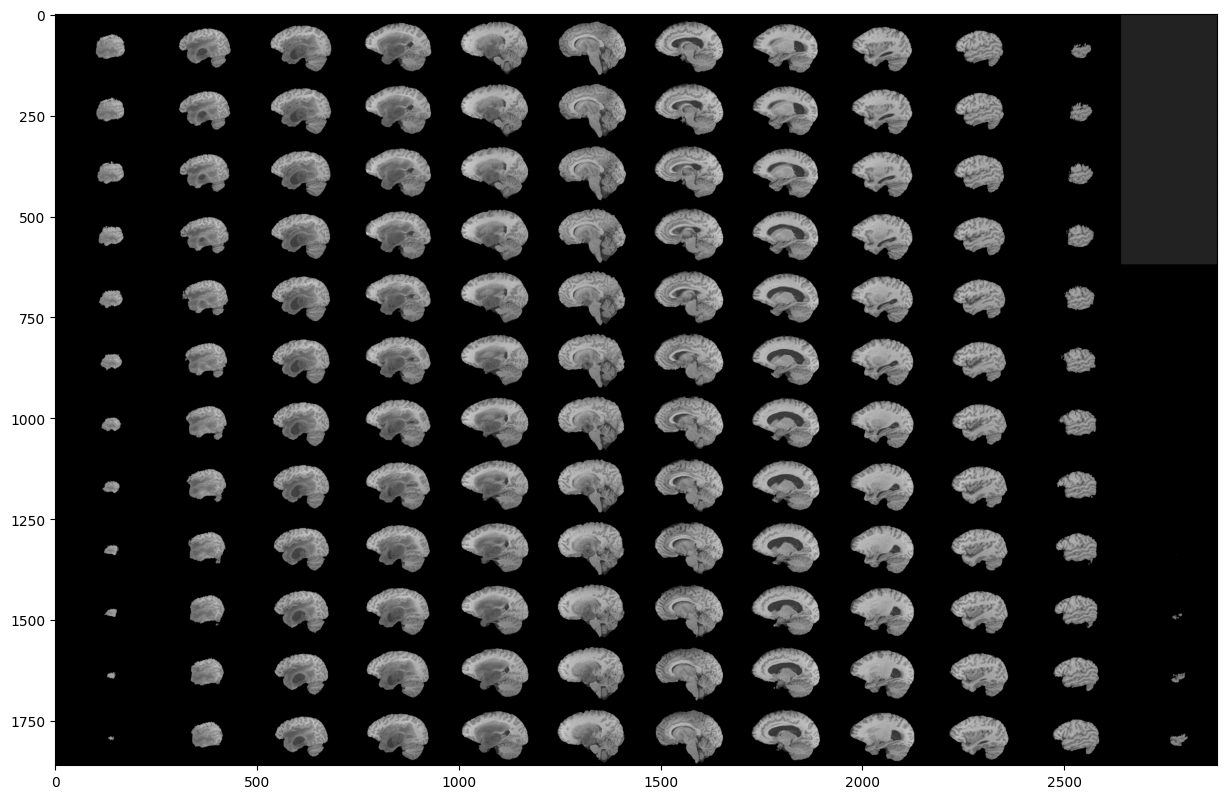

In [10]:
#skip 50:-50 slices since there is not much to see

fig,ax1 = plt.subplots(1, 1, figsize = (15,15))
ax1.imshow(rotate(montage(test_image_t1[50:-50,:,:]), 90, resize = True), cmap='gray')

# **SHOW SEGMENT OF TUMOR FOR EACH ABOVE SLICE**

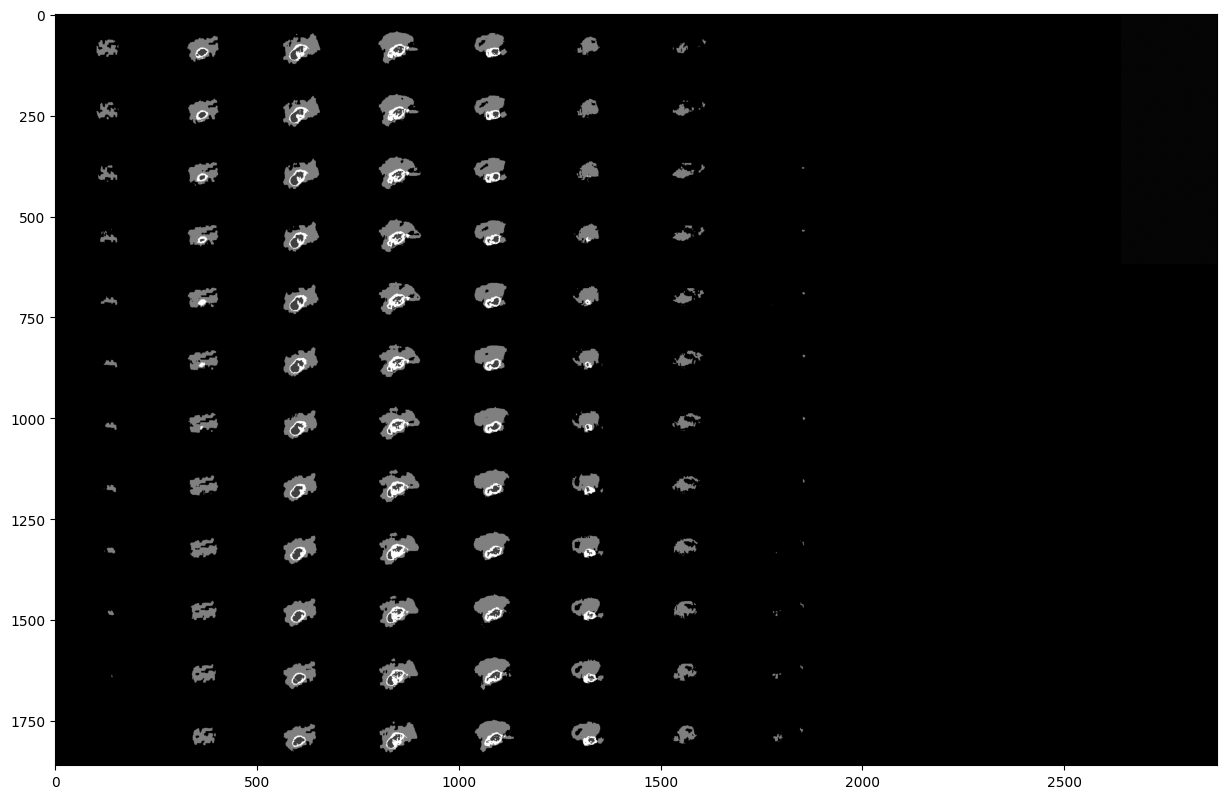

In [11]:
#skipping 50:-50
fig,ax1 = plt.subplots(1,1,figsize = (15,15))
ax1.imshow(rotate(montage(test_mask[50:-50,:,:]), 90, resize = True),cmap = 'gray')

# **GIF REPRESENTATION OF SLICES IN 3D VOL.**





In [12]:
from gif_your_nifti.core import write_gif_normal

shutil.copy2(TRAIN_DATASET_PATH + '/BraTS20_Training_001/BraTS20_Training_001_flair.nii', './test_gif_BraTS20_Training_001_flair.nii')
write_gif_normal('./test_gif_BraTS20_Training_001_flair.nii')

**SHOW SEGMENTS OF TUMOR USING DIFFERENT EFFECTS**



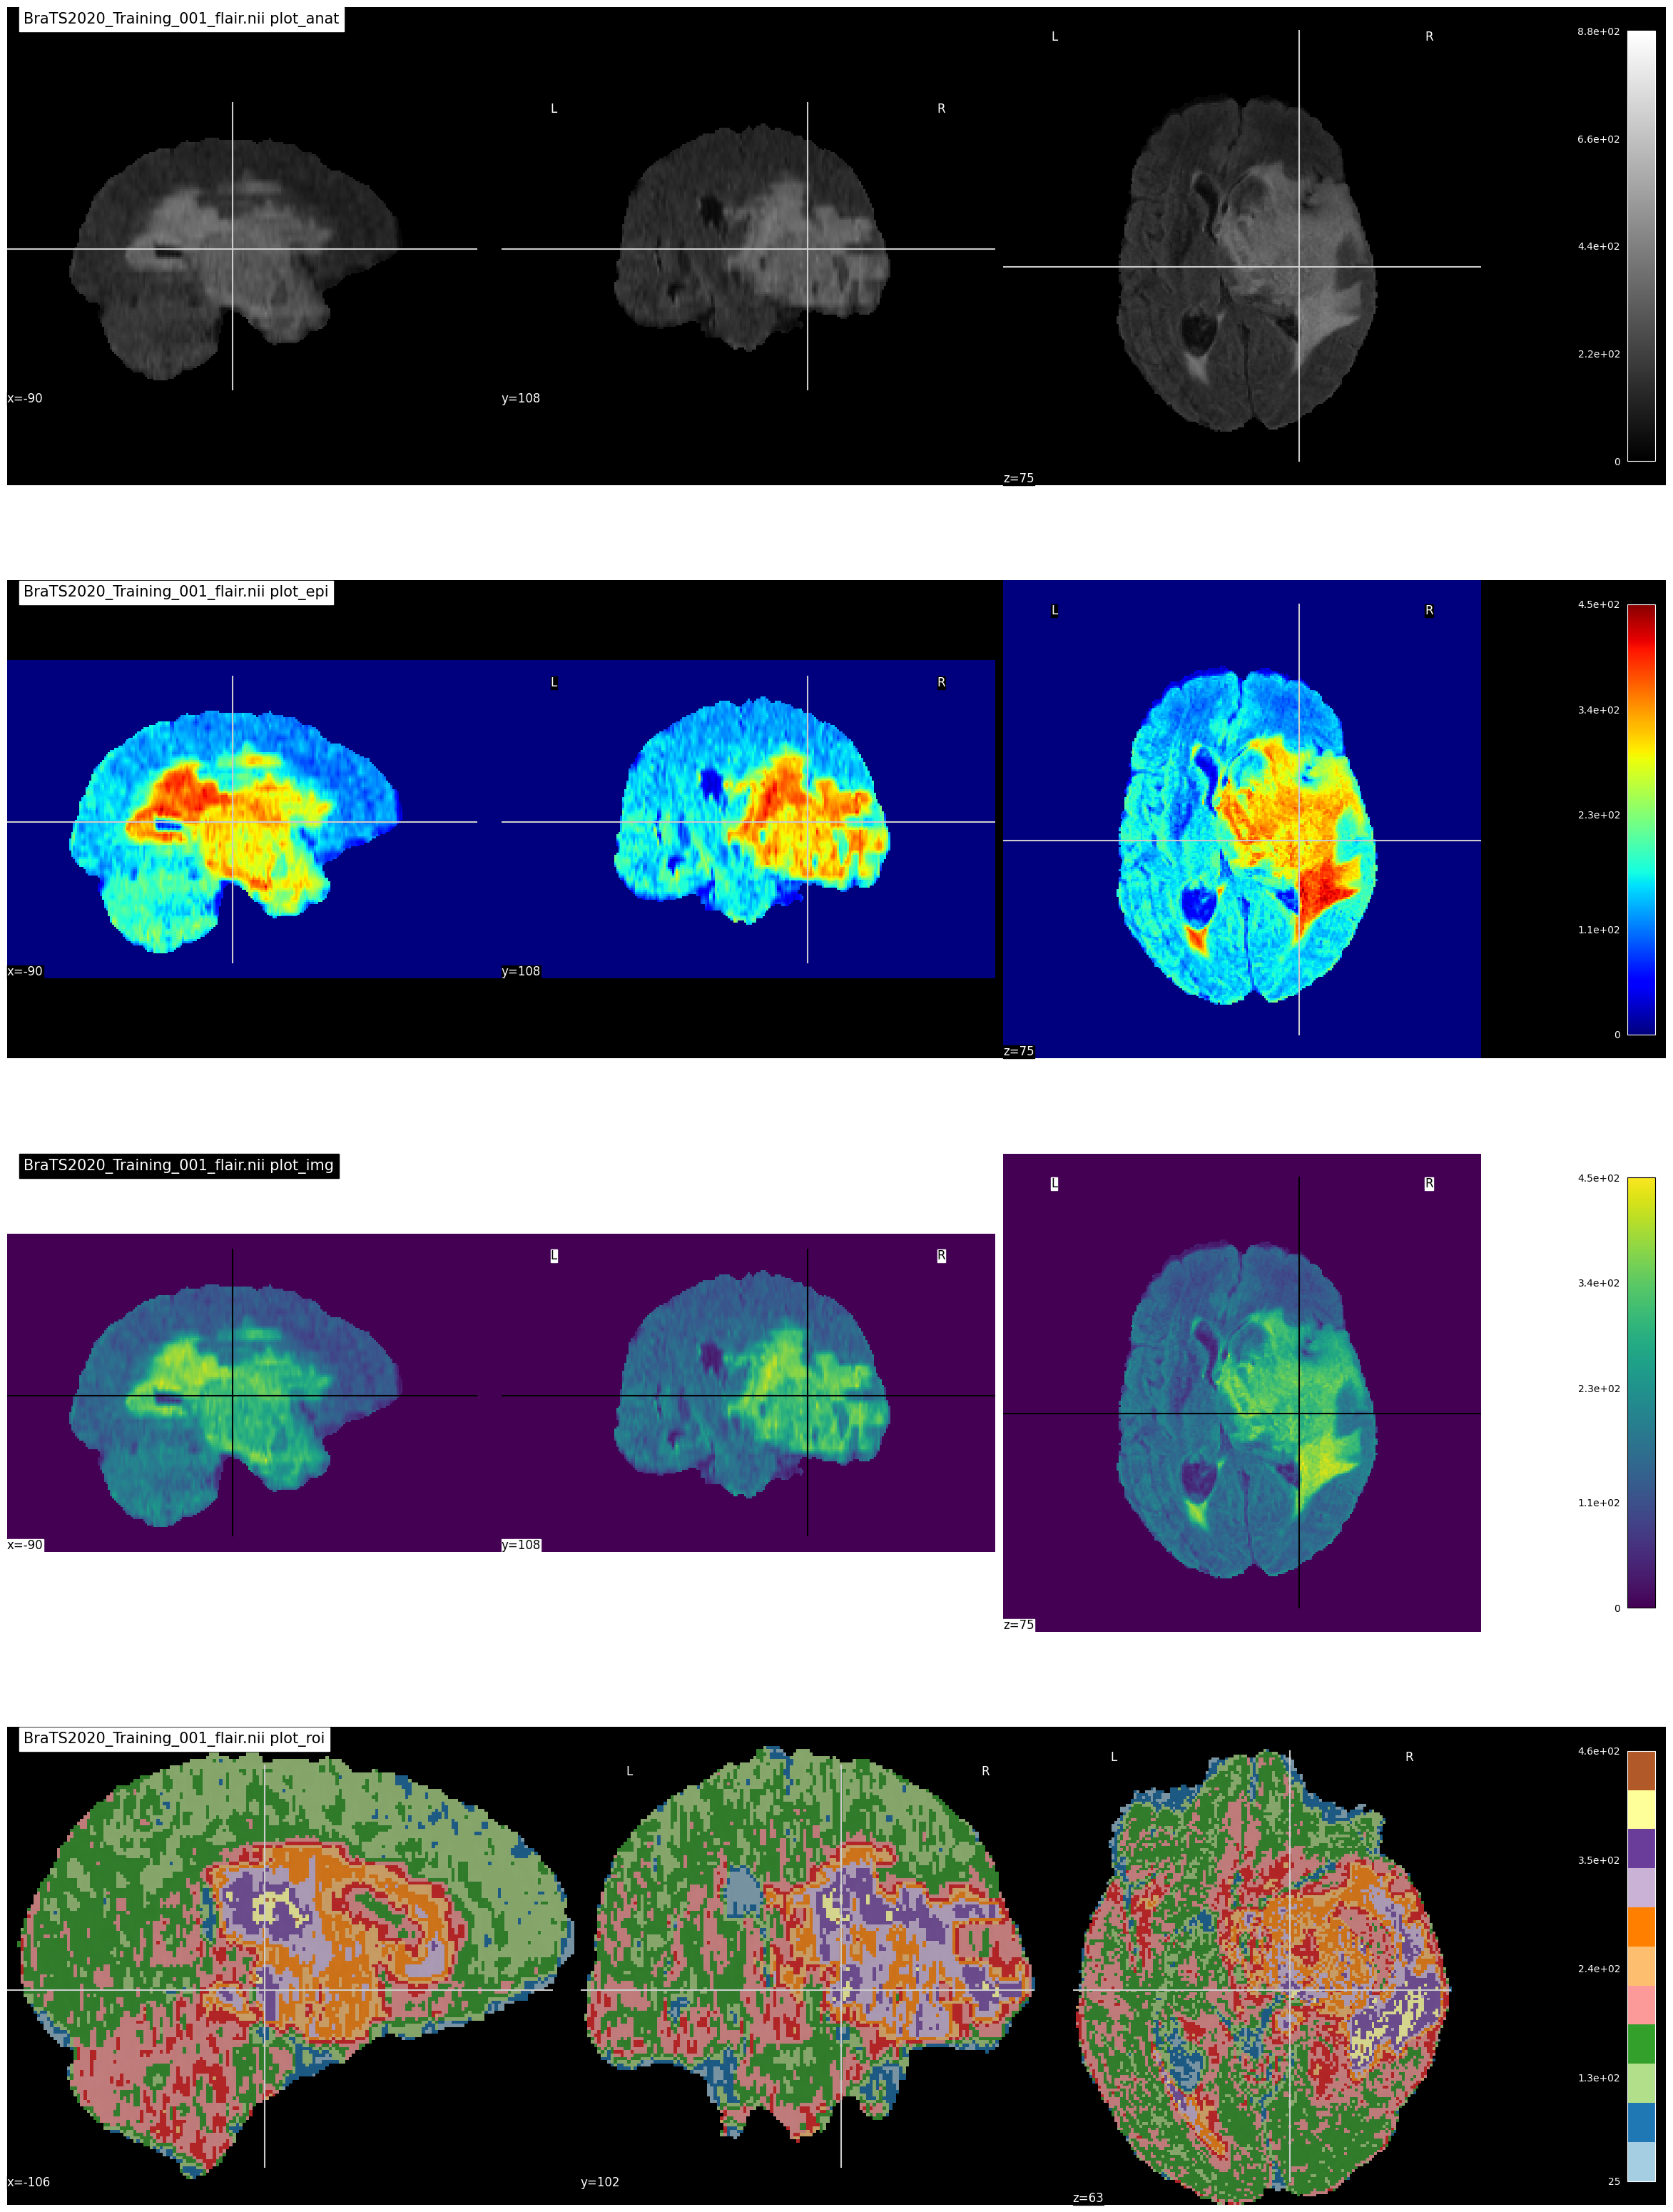

In [13]:
niimg = nl.image.load_img(TRAIN_DATASET_PATH + '/BraTS20_Training_001/BraTS20_Training_001_flair.nii')

nimask = nl.image.load_img(TRAIN_DATASET_PATH + '/BraTS20_Training_001/BraTS20_Training_001_seg.nii')

fig,axes = plt.subplots(nrows=4, figsize = (30, 40))

nlplt.plot_anat(niimg,title='BraTS2020_Training_001_flair.nii plot_anat', axes = axes[0])

nlplt.plot_epi(niimg,title='BraTS2020_Training_001_flair.nii plot_epi', bg_img=niimg, axes=axes[1], cmap='jet')

nlplt.plot_img(niimg,title='BraTS2020_Training_001_flair.nii plot_img',bg_img=niimg, axes=axes[2], cmap = 'viridis')

nlplt.plot_roi(niimg,title='BraTS2020_Training_001_flair.nii plot_roi', bg_img=niimg, axes=axes[3], cmap='Paired')

plt.show()

In [14]:
#Dice loss as defined above for 4 classes
def dice_coef(y_true, y_pred, smooth=1):
    class_num = 4
    total_loss = 0.0
    for i in range (class_num):
        y_true_f = tf.reshape(y_true[:,:,:,i], [-1])
        y_pred_f = tf.reshape(y_pred[:,:,:,i], [-1])
        intersection = tf.reduce_sum(y_true_f * y_pred_f)
        loss = ((2. * intersection + smooth)/(tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth))

        if i == 0:
            total_loss = loss
        else:
            total_loss = total_loss + loss

    total_loss = total_loss/class_num
    return total_loss

In [15]:
#define per class evaluation of dice coef
def dice_coef_necrotic(y_true, y_pred, epsilon=1e-6):
    intersection = tf.reduce_sum(tf.abs(y_true[:,:,:,1] * y_pred[:,:,:,1]))
    return (2. * intersection) / (tf.reduce_sum(tf.square(y_true[:,:,:,1]))+ tf.reduce_sum(tf.square(y_pred[:,:,:,1]))+ epsilon)

def dice_coef_edema(y_true, y_pred, epsilon=1e-6):
    intersection = tf.reduce_sum(tf.abs(y_true[:,:,:,2]*y_pred[:,:,:,2]))
    return (2. *intersection)/(tf.reduce_sum(tf.square(y_true[:,:,:,2])) + tf.reduce_sum(tf.square(y_pred[:,:,:,2]))+ epsilon)

def dice_coef_enhancing(y_true,y_pred,epsilon=1e-6):
    intersection = tf.reduce_sum(tf.abs(y_true[:,:,:,3]*y_pred[:,:,:,3]))
    return (2. * intersection) / (tf.reduce_sum(tf.square(y_true[:,:,:,3]))+ tf.reduce_sum(tf.square(y_pred[:,:,:,3]))+epsilon)

In [16]:
#Computing Precision
def precision(y_true,y_pred):
    true_positives = tf.reduce_sum(tf.round(tf.clip_by_value(y_true*y_pred, 0., 1.)))
    predicted_positives = tf.reduce_sum(tf.round(tf.clip_by_value(y_pred, 0., 1.)))
    precision = true_positives/(predicted_positives + 1e-7)
    return precision

In [17]:
#COMPUTING Sensitivity
def sensitivity(y_true,y_pred):
    true_positives = tf.reduce_sum(tf.round(tf.clip_by_value(y_true*y_pred, 0., 1.)))
    possible_positives = tf.reduce_sum(tf.round(tf.clip_by_value(y_true, 0., 1.)))
    return true_positives/(possible_positives + 1e-7)

In [18]:
#Computting Specificity
def specificity(y_true,y_pred):
    true_negatives = tf.reduce_sum(tf.round(tf.clip_by_value((1.-y_true)*(1.-y_pred), 0., 1.)))
    possible_negatives = tf.reduce_sum(tf.round(tf.clip_by_value(1.-y_true, 0., 1.)))
    return true_negatives/ (possible_negatives + 1e-7)

In [19]:
IMG_SIZE=128

In [20]:
def build_unet(inputs, ker_init, dropout):
    conv1 = Conv2D(32, 3, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(inputs)
    conv1 = Conv2D(32, 3, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(conv1)

    pool = MaxPooling2D(pool_size=(2, 2))(conv1)
    conv = Conv2D(64, 3, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(pool)
    conv = Conv2D(64, 3, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(conv)

    pool1 = MaxPooling2D(pool_size=(2, 2))(conv)
    conv2 = Conv2D(128, 3, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(pool1)
    conv2 = Conv2D(128, 3, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(conv2)

    pool2 = MaxPooling2D(pool_size=(2, 2))(conv2)
    conv3 = Conv2D(256, 3, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(pool2)
    conv3 = Conv2D(256, 3, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(conv3)


    pool4 = MaxPooling2D(pool_size=(2, 2))(conv3)
    conv5 = Conv2D(512, 3, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(pool4)
    conv5 = Conv2D(512, 3, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(conv5)
    drop5 = Dropout(dropout)(conv5)

    up7 = Conv2D(256, 2, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(UpSampling2D(size = (2,2))(drop5))
    merge7 = concatenate([conv3,up7], axis = 3)
    conv7 = Conv2D(256, 3, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(merge7)
    conv7 = Conv2D(256, 3, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(conv7)

    up8 = Conv2D(128, 2, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(UpSampling2D(size = (2,2))(conv7))
    merge8 = concatenate([conv2,up8], axis = 3)
    conv8 = Conv2D(128, 3, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(merge8)
    conv8 = Conv2D(128, 3, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(conv8)

    up9 = Conv2D(64, 2, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(UpSampling2D(size = (2,2))(conv8))
    merge9 = concatenate([conv,up9], axis = 3)
    conv9 = Conv2D(64, 3, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(merge9)
    conv9 = Conv2D(64, 3, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(conv9)

    up = Conv2D(32, 2, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(UpSampling2D(size = (2,2))(conv9))
    merge = concatenate([conv1,up], axis = 3)
    conv = Conv2D(32, 3, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(merge)
    conv = Conv2D(32, 3, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(conv)

    conv10 = Conv2D(4, (1,1), activation = 'softmax')(conv)

    return Model(inputs = inputs, outputs = conv10)

input_layer = Input((IMG_SIZE, IMG_SIZE, 2))

model = build_unet(input_layer, 'he_normal', 0.2)
model.compile(loss="categorical_crossentropy", optimizer=keras.optimizers.Adam(learning_rate=0.001), metrics = ['accuracy',tf.keras.metrics.MeanIoU(num_classes=4), dice_coef, precision, sensitivity, specificity, dice_coef_necrotic, dice_coef_edema ,dice_coef_enhancing] )

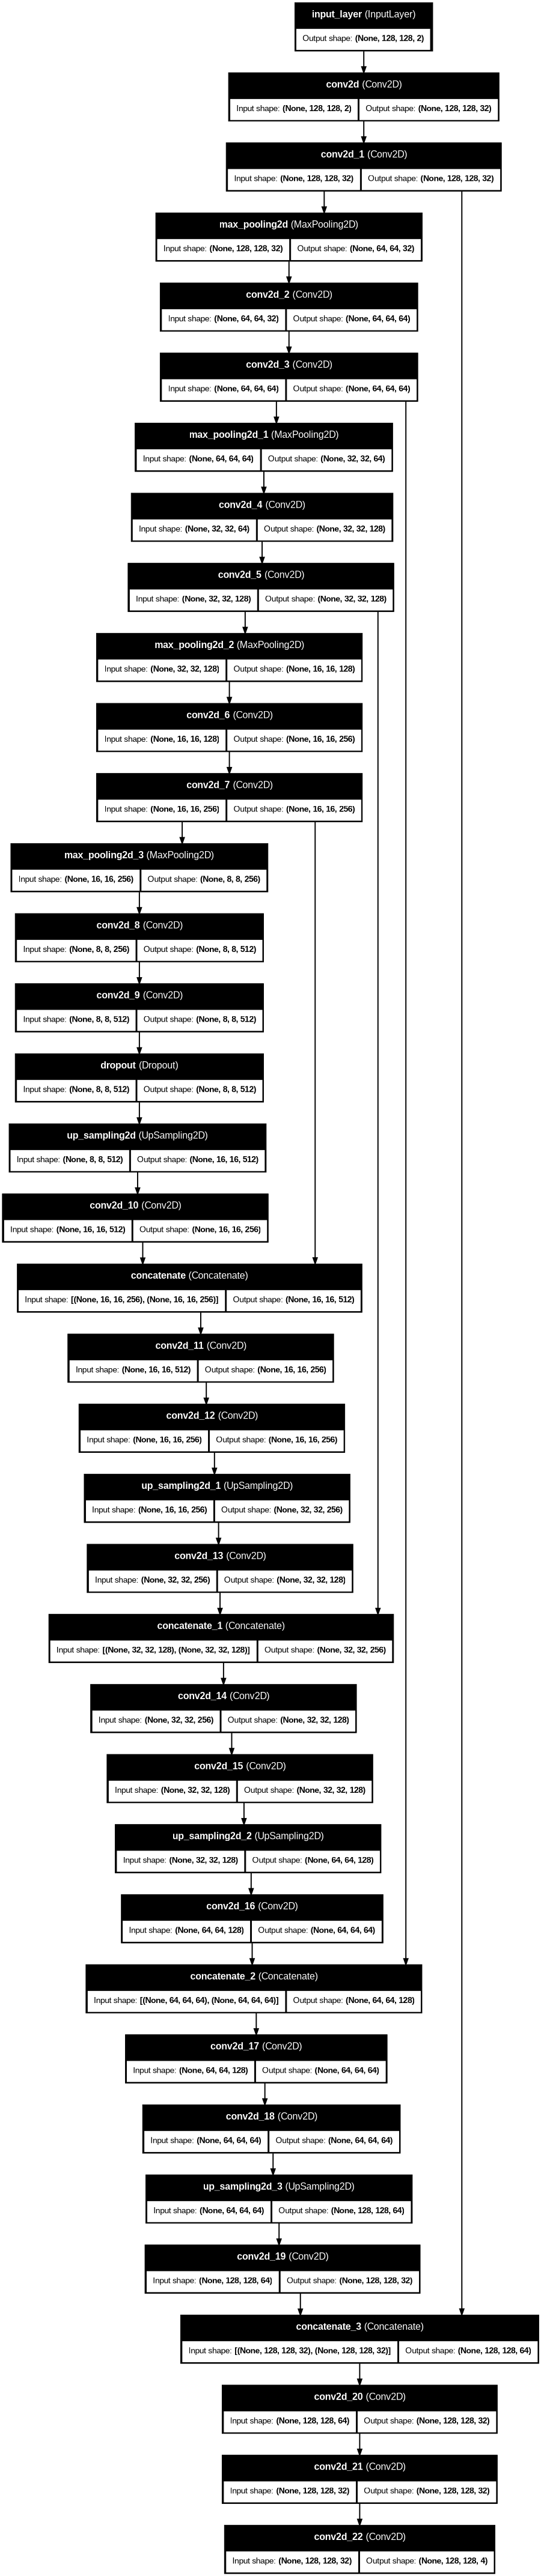

In [21]:
plot_model(model,
           show_shapes = True,
           show_dtype=False,
           show_layer_names = True,
           rankdir = 'TB',
           expand_nested = False,
           dpi = 70)

In [22]:
# Now that the naming is corrected in our writable path, we don't need to drop the folder anymore
train_and_val_directories = [f.path for f in os.scandir(TRAIN_DATASET_PATH) if f.is_dir()]
print(f"Total valid training directories loaded: {len(train_and_val_directories)}")
# file BraTS20_Training_355 has ill formatted name for for seg.nii file
train_and_val_directories.remove(TRAIN_DATASET_PATH+'/BraTS20_Training_355')

Total valid training directories loaded: 369


In [23]:
import os
import nibabel as nib
import numpy as np


# আপনার BraTS20 Training Data ফোল্ডারের পাথ এখানে দিন
DATA_DIR = "/kaggle/input/brats20-dataset-training-validation/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData"

# স্ট্যান্ডার্ড ৫টি ফাইল যা প্রতি ফোল্ডারে থাকা বাধ্যতামূলক
REQUIRED_SUFFIXES = ["_flair.nii", "_t1.nii", "_t1ce.nii", "_t2.nii", "_seg.nii"]

def check_brats_dataset(data_dir):
    print("🔍 BraTS 2020 ডেটাসেট পরীক্ষা করা শুরু হচ্ছে...\n")

    if not os.path.exists(data_dir):
        print(f"❌ ভুল পাথ! {data_dir} নামের কোনো ফোল্ডার পাওয়া যায়নি।")
        return

    subject_folders = [f for f in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, f))]
    print(f"📂 মোট সাবজেক্ট ফোল্ডার পাওয়া গেছে: {len(subject_folders)}\n")

    corrupt_files = []
    naming_errors = []
    missing_files = []
    shape_mismatches = []

    for folder in sorted(subject_folders):
        folder_path = os.path.join(data_dir, folder)
        existing_files = os.listdir(folder_path)

        # ১. ফাইলের নাম এবং উপস্থিতি পরীক্ষা (Naming & Missing File Check)
        for suffix in REQUIRED_SUFFIXES:
            expected_name = f"{folder}{suffix}"
            if expected_name not in existing_files:
                # নাম সামান্য ভুল থাকলে (যেমন কেস-সেন্সিটিভ বা টাইপো) তা খোঁজা
                matched_alternatives = [f for f in existing_files if suffix in f]
                if matched_alternatives:
                    naming_errors.append(f"⚠️ ভুল নাম: ফোল্ডার {folder}-এ ফাইলটি হওয়া উচিত ছিল '{expected_name}', কিন্তু আছে '{matched_alternatives[0]}'")
                else:
                    missing_files.append(f"❌ অনুপস্থিত ফাইল: ফোল্ডার {folder}-এ '{expected_name}' ফাইলটি নেই।")
                continue

            # ২. ফাইল করাপ্টেড কি না এবং ডাইমেনশন ঠিক আছে কি না পরীক্ষা (Integrity Check)
            file_path = os.path.join(folder_path, expected_name)
            try:
                # মেমোরি বাঁচাতে অলস লোড (Lazy load) করা হচ্ছে
                img = nib.load(file_path)

                # হেডার ও ডেটার গঠন ভ্যালিডেশন
                shape = img.shape

                # স্ট্যান্ডার্ড BraTS 2020 সাইজ হলো (240, 240, 155)
                if shape != (240, 240, 155):
                    shape_mismatches.append(f"📐 ডাইমেনশন অমিল: {expected_name} এর সাইজ {shape}, যা স্ট্যান্ডার্ড (240, 240, 155) নয়।")

                # ডেটা অবজেক্টটি আসলেই রিড করা যাচ্ছে কি না পরীক্ষা করা
                _ = img.dataobj[0, 0, 0]

            except Exception as e:
                corrupt_files.append(f"💥 করাপ্টেড ফাইল: {file_path} লোড করা যাচ্ছে না। এরর: {str(e)}")

    # 📊 চূড়ান্ত রিপোর্ট প্রিন্ট করা
    print("="*50)
    print("📊 পরীক্ষা সম্পন্ন! চূড়ান্ত ফলাফল রিপোর্ট:")
    print("="*50)

    if not any([naming_errors, missing_files, corrupt_files, shape_mismatches]):
        print("✅ অভিনন্দন! আপনার ডেটাসেটের সব ফাইলের নাম, সাইজ এবং ফরম্যাট একদম সঠিক আছে।")
        return

    if naming_errors:
        print(f"\n[ভুল নামের তালিকা - মোট {len(naming_errors)}টি]:")
        for err in naming_errors: print(err)

    if missing_files:
        print(f"\n[অনুপস্থিত ফাইলের তালিকা - মোট {len(missing_files)}টি]:")
        for err in missing_files: print(err)

    if corrupt_files:
        print(f"\n[করাপ্টেড/ভাঙা ফাইলের তালিকা - মোট {len(corrupt_files)}টি]:")
        for err in corrupt_files: print(err)

    if shape_mismatches:
        print(f"\n[ভুল ডাইমেনশনের তালিকা - মোট {len(shape_mismatches)}টি]:")
        for err in shape_mismatches: print(err)

# স্ক্রিপ্টটি রান করুন
check_brats_dataset(DATA_DIR)



🔍 BraTS 2020 ডেটাসেট পরীক্ষা করা শুরু হচ্ছে...

📂 মোট সাবজেক্ট ফোল্ডার পাওয়া গেছে: 369

📊 পরীক্ষা সম্পন্ন! চূড়ান্ত ফলাফল রিপোর্ট:

[অনুপস্থিত ফাইলের তালিকা - মোট 1টি]:
❌ অনুপস্থিত ফাইল: ফোল্ডার BraTS20_Training_355-এ 'BraTS20_Training_355_seg.nii' ফাইলটি নেই।


In [24]:
train_and_val_directories = [f.path for f in os.scandir(TRAIN_DATASET_PATH) if f.is_dir()]


# file BraTS20_Training_355 has ill formatted name for for seg.nii file
train_and_val_directories.remove(TRAIN_DATASET_PATH+'/BraTS20_Training_355')

# file BraTS20_Training_355 has ill formatted name for seg.nii file
target_path = os.path.join(TRAIN_DATASET_PATH, 'BraTS20_Training_355')
if target_path in train_and_val_directories:
    train_and_val_directories.remove(target_path)

In [25]:
#lists of directories with studies
train_and_val_directories = [f.path for f in os.scandir(TRAIN_DATASET_PATH) if f.is_dir()]

def path_list_into_IDS(dirList):
    x=[]
    for i in range (0,len(dirList)):
        x.append(dirList[i][dirList[i].rfind('/')+1:])
    return x

train_and_test_ids = path_list_into_IDS(train_and_val_directories)

train_test_ids, val_ids = train_test_split(train_and_test_ids,test_size = 0.2)
train_ids,test_ids = train_test_split(train_test_ids,test_size=0.15)


In [26]:
#Overriding Keras sequence DataGenerator class
from numpy.random import shuffle
class DataGenerator (keras.utils.Sequence):
    'Generate Data for Keras'
    def __init__(self, list_IDs, dim=(IMG_SIZE,IMG_SIZE), batch_size = 1, n_channels = 2, shuffle = True):
        'Initialization'
        self.dim=dim
        self.batch_size= batch_size
        self.list_IDs= list_IDs
        self.n_channels=n_channels
        self.shuffle=shuffle
        self.on_epoch_end()

    def __len__(self):
        'denotes the number of batches per epoch'
        return int(np.floor(len(self.list_IDs)/ self.batch_size))

    def __getitem__(self, index):
        'Generate one batch of Data'
        #Generate indexes of the batch
        indexes = self.indexes[index*self.batch_size:(index+1)*self.batch_size]

        #Find List of IDs
        Batch_ids=[self.list_IDs[k] for k in indexes]

        #Generate Data
        X,Y = self.__data__generation(Batch_ids)
        return X,Y
    def on_epoch_end(self):
        'Updates indexes after each epoch'
        self.indexes = np.arange(len(self.list_IDs))
        if self.shuffle == True:
            np.random.shuffle(self.indexes)


    def __data__generation(self, Batch_ids):
        'Generates data containing batch_size samples'
        #X= (n_samples, *dim, n_channels)
        #Initialization
        X = np.zeros((self.batch_size*VOLUME_SLICES, *self.dim, self.n_channels), dtype=np.float32)
        Y = np.zeros((self.batch_size*VOLUME_SLICES, *self.dim, 4), dtype=np.float32)

        # Generate data
        for c, i in enumerate(Batch_ids):
            case_path = os.path.join(TRAIN_DATASET_PATH,i)
            data_path = os.path.join(case_path, f'{i}_flair.nii')
            flair = nib.load(data_path).get_fdata()
            data_path = os.path.join(case_path, f'{i}_t1ce.nii')
            ce = nib.load(data_path).get_fdata()
            data_path = os.path.join(case_path, f'{i}_seg.nii')
            seg = nib.load(data_path).get_fdata()

            for j in range (VOLUME_SLICES):
                slice_idx = j + VOLUME_SLICES*c
                # Resize and normalization for input channels
                X[slice_idx,:,:,0]= cv2.resize(flair[:,:,j+VOLUME_START_AT], (IMG_SIZE,IMG_SIZE))
                X[slice_idx,:,:,1]= cv2.resize(ce[:,:,j+VOLUME_START_AT], (IMG_SIZE,IMG_SIZE))

                # Resize segmentation mask slice
                seg_slice = cv2.resize(seg[:,:,j+VOLUME_START_AT], (IMG_SIZE,IMG_SIZE), interpolation=cv2.INTER_NEAREST)
                seg_slice[seg_slice == 4] = 3

                # Pure NumPy One-hot encoding for the current slice
                mask = np.zeros((IMG_SIZE, IMG_SIZE, 4), dtype=np.float32)
                for k in range(4):
                    mask[:, :, k] = (seg_slice == k).astype(np.float32)
                Y[slice_idx] = mask

        # Prevent division by zero if max(X) is 0
        max_val = np.max(X)
        if max_val > 0:
            X = X / max_val

        return X, Y

training_generator = DataGenerator(train_ids)
valid_generator = DataGenerator(val_ids)
test_generator = DataGenerator(test_ids)

/tmp/ipykernel_2348/330513193.py:4: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


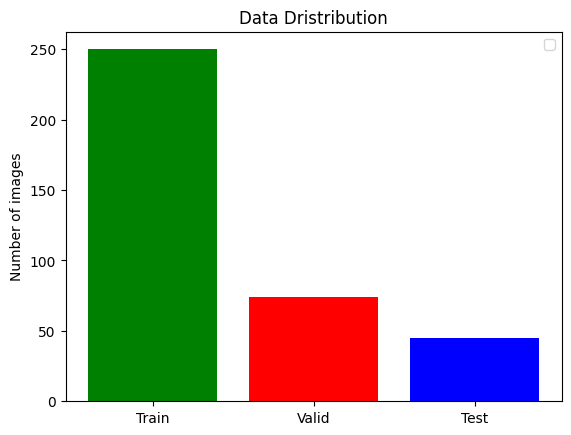

In [27]:
#Show number of data for each dir
def show_data_layout():
    plt.bar(["Train","Valid","Test"],[len(train_ids),len(val_ids),len(test_ids)], align = 'center', color=['green','red','blue'])
    plt.legend()
    plt.ylabel('Number of images')
    plt.title('Data Dristribution')
    plt.show()
show_data_layout()

In [28]:
csv_logger= CSVLogger('training.log', separator='.', append=False)
callbacks = [keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=2, min_lr=0.000001, verbose=1),csv_logger]

In [29]:
# Fix the callback monitor typo ('val_los' -> 'val_loss') directly before training
for cb in callbacks:
    if hasattr(cb, 'monitor') and cb.monitor == 'val_los':
        cb.monitor = 'val_loss'

# Train model
K.clear_session()
history = model.fit(training_generator, epochs=15, steps_per_epoch=len(train_ids), callbacks=callbacks, validation_data=valid_generator)
model.save('3D_MRI_BRAIN_TUMOR_SEGMENTATION.h5')

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 334s 1s/step - accuracy: 0.9758 - dice_coef: 0.2646 - dice_coef_edema: 0.1097 - dice_coef_enhancing: 0.0442 - dice_coef_necrotic: 0.0484 - loss: 0.2844 - mean_io_u: 0.5727 - precision: 0.9606 - sensitivity: 0.9524 - specificity: 0.9947 - val_accuracy: 0.9826 - val_dice_coef: 0.2773 - val_dice_coef_edema: 0.1661 - val_dice_coef_enhancing: 0.0648 - val_dice_coef_necrotic: 0.0541 - val_loss: 0.0699 - val_mean_io_u: 0.6699 - val_precision: 0.9827 - val_sensitivity: 0.9826 - val_specificity: 0.9942 - learning_rate: 0.0010
Epoch 2/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 231s 924ms/step - accuracy: 0.9832 - dice_coef: 0.2841 - dice_coef_edema: 0.1583 - dice_coef_enhancing: 0.0776 - dice_coef_necrotic: 0.0796 - loss: 0.0689 - mean_io_u: 0.6641 - precision: 0.9844 - sensitivity: 0.9817 - specificity: 0.9948 - val_accuracy: 0.9826 - val_dice_coef: 0.2807 - val_dice_coef_edema: 0.1369 - val_dice_coef_enhancing: 0.0521 - val_dice_coef_necrotic: 0.0402 - val_loss: 0.

In [30]:
model.save('3D_MRI_BRAIN_TUMOR_SEGMENTATION.h5')
keras.saving.save_model(model, 'my_model.keras')
show_path=keras.saving.save_model(model, 'my_model.keras')
print(show_saved_model_path)


NameError: name 'show_saved_model_path' is not defined

In [33]:
from pathlib import Path

# Resolve absolute path of the saved model
model_path = Path("3D_MRI_BRAIN_TUMOR_SEGMENTATION.h5")  # or "saved_model_directory"
print("Absolute Path:", model_path.resolve())


Absolute Path: /content/3D_MRI_BRAIN_TUMOR_SEGMENTATION.h5


In [35]:
import tensorflow as tf
import numpy as np
import nibabel as nib
import cv2

#load the saved model
model = tf.keras.models.load_model('3D_MRI_BRAIN_TUMOR_SEGMENTATION.h5', custom_objects={
    'dice_coef': dice_coef,
    'precision': precision,
    'sensitivity': sensitivity,
    'specificity': specificity,
    'dice_coef_necrotic': dice_coef_necrotic,
    'dice_coef_edema': dice_coef_edema,
    'dice_coef_enhancing': dice_coef_enhancing
})

def preprocess_image(image_file, slice_index=None):
    #Load the NIFTI file
    img = nib.load(image_file).get_fdata()

    #Select a specific slice if needed
    if slice_index is not None:
        img = img[:, :, slice_index]

    image_resized = cv2.resize(img, (IMG_SIZE, IMG_SIZE))

    #Normalize the image
    image_resized = image_resized / np.max(image_resized)
    return image_resized

def predict(image_paths, slice_index):
    X = np.zeros((1, IMG_SIZE, IMG_SIZE, 2))

    #process specific slices from the images
    X[0, :, :, 0] = preprocess_image(image_paths[0], slice_index)
    X[0, :, :, 1] = preprocess_image(image_paths[1], slice_index)

    pred = model.predict(X)
    return np.argmax(pred[0], axis=-1)

#Example usage
image_paths = [
    '/kaggle/input/brats20-dataset-training-validation/BraTS2020_ValidationData/MICCAI_BraTS2020_ValidationData/BraTS20_Validation_010/BraTS20_Validation_010_flair.nii',
    '/kaggle/input/brats20-dataset-training-validation/BraTS2020_ValidationData/MICCAI_BraTS2020_ValidationData/BraTS20_Validation_010/BraTS20_Validation_010_t1ce.nii'
]

slice_index = 75
prediction = predict(image_paths, slice_index)

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step


In [36]:
import numpy as np
def get_classification(pred):
    #Get the class with the highest probability for each pixel
    class_predictions = np.argmax(pred, axis=-1)
    return class_predictions

In [37]:
get_classification(prediction)

array([ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0, 35, 35, 34, 33, 33, 33, 33, 33, 36,
       36, 74, 73, 94, 87, 85, 85, 85, 85, 85, 84, 82, 79, 78, 78, 77, 77,
       78, 78, 78, 79, 86, 81,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0])

In [38]:
import matplotlib.pyplot as plt
def visualize_prediction(prediction):
    plt.imshow(prediction,cmap='nipy_spectral')
    plt.title('Prediction Segmentation')
    plt.colorbar()
    plt.show()


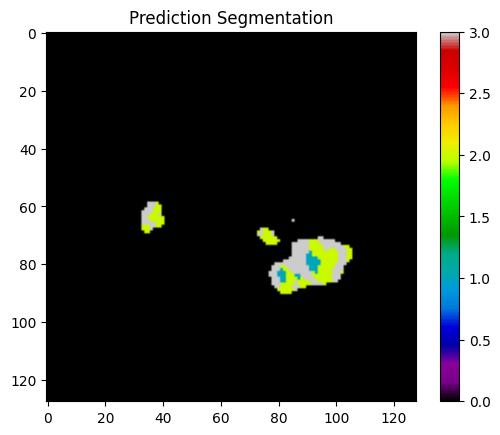

In [39]:
visualize_prediction(prediction)

In [ ]:
## Load Trained model ###
model = tf.keras.models.load_model('')